# T03 · Earth Engine spike

Checks that Earth Engine works from Python for the team project. It then computes, for the hero wetland, the metrics the rating needs (dev-spec §7.2): **Dynamic World land-cover fractions** and a **monthly NDVI series** with a 5-year Sen's slope trend. Findings are in [ADR-0004](../docs/adr/0004-earth-observation.md).

**Run** (from the repo root; needs `EE_SERVICE_ACCOUNT_JSON` in `.env`, see `make check-keys`):
```bash
cd backend && uv run --with earthengine-api --with jupyter --with matplotlib \
  jupyter nbconvert --execute --to notebook --inplace ../notebooks/ee_spike.ipynb
```

**Sources:** Dynamic World V1, `GOOGLE/DYNAMICWORLD/V1`, CC-BY 4.0. Sentinel-2 SR Harmonized, `COPERNICUS/S2_SR_HARMONIZED`. Cloud Score+, `GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED` (`cs_cdf` ≥ 0.60, per its catalog page). `ee.Reducer.sensSlope` per ADR-0001.

In [1]:
import json
import sys
import time
from pathlib import Path

import ee

sys.path.insert(0, str(Path.cwd().parent / "backend"))
from app.config import get_settings  # noqa: E402  (reads ../.env)
from app.tools.geometry import validate_polygon  # noqa: E402

settings = get_settings()
key_path = Path(settings.ee_service_account_json).expanduser()
key = json.loads(key_path.read_text())
credentials = ee.ServiceAccountCredentials(key["client_email"], str(key_path))
ee.Initialize(credentials, project=key["project_id"])
print("Earth Engine initialised with the service account from EE_SERVICE_ACCOUNT_JSON")

Earth Engine initialised with the service account from EE_SERVICE_ACCOUNT_JSON


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Metric functions
Each returns plain numbers; one `getInfo()` per metric keeps it fast.
- **Land cover:** per-pixel **mode** of the Dynamic World `label` over the last 12 months, then each class's share of pixels at 10 m.
- **NDVI:** Sentinel-2 SR, cloud-masked with Cloud Score+ (`cs_cdf` ≥ 0.60), with water pixels (Dynamic World mode = water) excluded. For each month, the median NDVI composite, then its mean over the polygon. The trend is Sen's slope over the monthly means, in NDVI per year.

In [2]:
CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops", "shrub_and_scrub", "built", "bare", "snow_and_ice"]
NATURAL = ["water", "trees", "grass", "flooded_vegetation", "shrub_and_scrub"]
END = ee.Date("2026-10-01")
START_12M = END.advance(-12, "month")
START_5Y = END.advance(-5, "year")
CLEAR = 0.60
cs_plus = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")


def dw_mode(aoi):
    return ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterBounds(aoi).filterDate(START_12M, END).select("label").mode()


def land_cover(aoi):
    t0 = time.perf_counter()
    hist = dw_mode(aoi).reduceRegion(ee.Reducer.frequencyHistogram(), aoi, scale=10, maxPixels=1e9).get("label").getInfo()
    total = sum(hist.values())
    fractions = {CLASSES[int(k)]: v / total for k, v in sorted(hist.items(), key=lambda kv: -kv[1])}
    return fractions, time.perf_counter() - t0


def ndvi_series(aoi):
    t0 = time.perf_counter()
    water = dw_mode(aoi).eq(0)
    s2 = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(START_5Y, END)
        .linkCollection(cs_plus, ["cs_cdf"])
        .map(lambda img: img.updateMask(img.select("cs_cdf").gte(CLEAR)).updateMask(water.Not()))
        .map(lambda img: img.normalizedDifference(["B8", "B4"]).rename("ndvi").copyProperties(img, ["system:time_start"]))
    )

    def monthly(i):
        start = START_5Y.advance(i, "month")
        month = s2.filterDate(start, start.advance(1, "month"))
        mean = month.median().reduceRegion(ee.Reducer.mean(), aoi, scale=10, maxPixels=1e9).get("ndvi")
        return ee.Feature(None, {"month": start.format("YYYY-MM"), "t": start.difference(START_5Y, "year"), "ndvi": mean, "images": month.size()})

    series = ee.FeatureCollection(ee.List.sequence(0, 59).map(monthly)).filter(ee.Filter.notNull(["ndvi"]))
    rows = [f["properties"] for f in series.getInfo()["features"]]
    trend = series.reduceColumns(ee.Reducer.sensSlope(), ["t", "ndvi"]).getInfo()
    return rows, trend, time.perf_counter() - t0


def report(name, geojson):
    aoi = ee.Geometry(geojson)
    ours = validate_polygon(geojson).area_ha
    ee_ha = aoi.area(maxError=1).getInfo() / 10_000
    fractions, t_lc = land_cover(aoi)
    rows, trend, t_ndvi = ndvi_series(aoi)
    last12 = rows[-12:]
    ndvi_mean = sum(r["ndvi"] for r in last12) / len(last12)
    natural = sum(fractions.get(c, 0) for c in NATURAL)
    print(f"== {name}")
    print(f"area: ours {ours:.1f} ha | Earth Engine {ee_ha:.1f} ha | diff {abs(ours - ee_ha) / ee_ha:.2%}")
    print(f"land cover ({t_lc:.1f} s): " + ", ".join(f"{k} {v:.1%}" for k, v in fractions.items() if v >= 0.005))
    print(f"natural fraction N = {natural:.1%}")
    print(f"NDVI ({t_ndvi:.1f} s): {len(rows)}/60 months with clear data, {sum(r['images'] for r in rows)} scenes, "
          f"mean last 12 months {ndvi_mean:.3f}, Sen's slope {trend['slope']:+.4f}/year")
    return rows, trend

## The seed's placeholder vs. the real wetland
The seed's placeholder box (`app/seed.py`) turns out to be **mostly built-up Xochimilco town**, not wetland. A scan of 1.5 km boxes nearby (next cell) finds the wetland about 3 km north-east, around Xochimilco Ecological Park and the Ejidos de Xochimilco. T11 should draw the real hero boundary there.

In [3]:
region = ee.Geometry.Rectangle([-99.12, 19.25, -99.02, 19.32])
mode = dw_mode(region)
step = 0.015
cells = [
    ee.Feature(ee.Geometry.Rectangle([lon, lat, lon + step, lat + step]), {"lon": round(lon, 3), "lat": round(lat, 3)})
    for lat in [19.25 + i * step for i in range(5)]
    for lon in [-99.12 + j * step for j in range(7)]
]
layers = ee.Image.cat([
    mode.eq(0).Or(mode.eq(3)).rename("wet"),
    mode.remap([0, 1, 2, 3, 5], [1, 1, 1, 1, 1], 0).rename("natural"),
    mode.eq(6).rename("built"),
])
scan = layers.reduceRegions(ee.FeatureCollection(cells), ee.Reducer.mean(), scale=10).getInfo()["features"]
print("natural   wet  built   1.5 km box SW corner (lon, lat)")
for f in sorted(scan, key=lambda f: -f["properties"]["natural"])[:5]:
    p = f["properties"]
    print(f"{p['natural']:6.1%} {p['wet']:6.1%} {p['built']:6.1%}   {p['lon']}, {p['lat']}")

natural   wet  built   1.5 km box SW corner (lon, lat)
 78.2%  24.7%  16.2%   -99.105, 19.28
 74.4%  13.5%  22.3%   -99.075, 19.265
 68.4%   8.1%  17.6%   -99.09, 19.265
 65.6%  41.9%  20.4%   -99.06, 19.265
 62.4%   0.4%  21.8%   -99.03, 19.31


In [4]:
SEED_PLACEHOLDER = {
    "type": "Polygon",
    "coordinates": [[[-99.10, 19.25], [-99.08, 19.25], [-99.08, 19.27], [-99.10, 19.27], [-99.10, 19.25]]],
}
WETLAND_CANDIDATE = {  # best box from the scan; T11 replaces it with a hand-drawn boundary
    "type": "Polygon",
    "coordinates": [[[-99.105, 19.28], [-99.09, 19.28], [-99.09, 19.295], [-99.105, 19.295], [-99.105, 19.28]]],
}
report("Seed placeholder", SEED_PLACEHOLDER)
rows, trend = report("Wetland candidate (Xochimilco Ecological Park area)", WETLAND_CANDIDATE)

== Seed placeholder
area: ours 465.5 ha | Earth Engine 466.9 ha | diff 0.30%
land cover (2.0 s): built 93.3%, trees 2.6%, grass 1.7%, crops 1.2%, water 0.7%, shrub_and_scrub 0.6%
natural fraction N = 5.5%
NDVI (4.7 s): 60/60 months with clear data, 392 scenes, mean last 12 months 0.358, Sen's slope +0.0061/year


== Wetland candidate (Xochimilco Ecological Park area)
area: ours 261.8 ha | Earth Engine 262.6 ha | diff 0.30%
land cover (0.3 s): trees 33.7%, water 22.3%, built 16.2%, grass 10.3%, shrub_and_scrub 9.5%, crops 5.6%, flooded_vegetation 2.4%
natural fraction N = 78.2%
NDVI (12.7 s): 60/60 months with clear data, 392 scenes, mean last 12 months 0.581, Sen's slope +0.0101/year


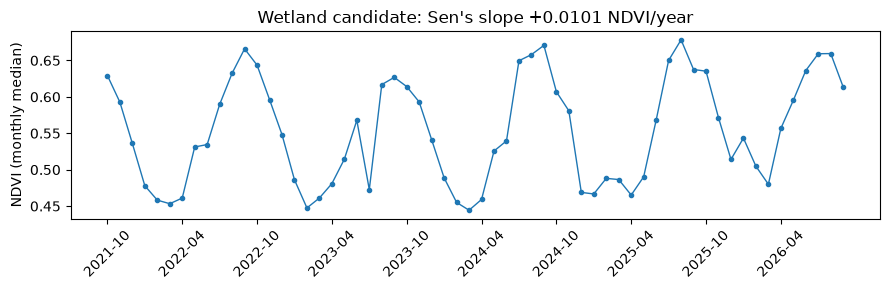

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot([r["month"] for r in rows], [r["ndvi"] for r in rows], marker=".", linewidth=1)
ax.set_xticks([r["month"] for r in rows][::6])
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("NDVI (monthly median)")
ax.set_title(f"Wetland candidate: Sen's slope {trend['slope']:+.4f} NDVI/year")
fig.tight_layout()